In [1]:
import json
import random
import base64
import os
import shutil
import subprocess
import dill
import nltk
import itertools
import io
import math
import textwrap
import shared.taxonomy as taxonomy
import time
import numpy as np
import evaluate

from PIL import Image
from pathlib import Path
from collections import Counter

from scipy import stats
import numpy as np

/Users/aadi.joshi/miniconda3/envs/general/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Settings

In [2]:
HUMAN_ANNOTATIONS_FILE_PATH = None #Path('./aj_main.json')

MODEL_RESPONSES_FILE_PATH = Path('responses_judge_gpt_54_family.dill')

input_types = [
    'images', 
    'latex', 
    'images_and_latex'
]

input_types_to_name = {
    'images': 'Images',
    'latex': 'Latex',
    'images_and_latex': r'Images \& Latex',
}

error_categories = [
    'contradiction_with_established_knowledge', 
    'logically_invalid_interpretation', 
    'methodology_result_conflict', 
    'semantic_misinterpretation', 
    'suboptimal_methodology'
]

error_cat_to_acronym = {
    'contradiction_with_established_knowledge': 'ConEK',
    'logically_invalid_interpretation': 'LogII',
    'methodology_result_conflict': 'MetRC',
    'semantic_misinterpretation': 'SemM',
    'suboptimal_methodology': 'SubM'
}

error_category_names = [taxonomy.TAXONOMY_DATA[cat]['name'] for cat in error_categories]
error_category_acronyms = [error_cat_to_acronym[cat] for cat in error_categories]

model_ids = [
    'gpt_54', 
    'gpt_54_mini',
    #'gpt_54_mini_low',
    'gpt_54_nano',
    #gpt_54_nano_low', 
    # 'gemini_25_flash', 
    # 'gemini_25_flash_lite', 
    # 'gemini_31_flash_lite', 
    # 'qwen_3_vl_30b_a3b_thinking', 
    # 'qwen_3_vl_8b_thinking', 
    # 'qwen_3_vl_8b_instruct'
]

model_id_to_name = {
    'gpt_54': 'GPT 5.4 (high)', 
    'gpt_54_mini': 'GPT 5.4-mini (high)',
    'gpt_54_nano': 'GPT 5.4-nano (high)',
    # 'gpt_54_mini_low': 'GPT 5.4-mini (low)',
    # 'gpt_54_nano_low': 'GPT 5.4-nano (low)',
    # 'gemini_25_flash': 'Gemini 2.5 Flash (dynamic)',
    # 'gemini_25_flash_lite': 'Gemini 2.5 Flash-lite (none)',
    # 'gemini_31_flash_lite': 'Gemini 3.1 Flash-lite (high)',
    # 'qwen_3_vl_30b_a3b_thinking': 'Qwen3-VL 30BA3B Thinking',
    # 'qwen_3_vl_8b_thinking': 'Qwen3-VL 8B Thinking',
    # 'qwen_3_vl_8b_instruct': 'Qwen3-VL 8B Instruct',
}

# thinking - non thinking stat comparisons
model_id_to_alt_thinking = {
    #'gpt_54': None,
    #'gpt_54_mini': 'gpt_54_mini_low',
    #'gpt_54_mini_low': 'gpt_54_mini',
    #'gpt_54_nano': 'gpt_54_nano_low',
    #'gpt_54_nano_low': 'gpt_54_nano',
    #'gemini_25_flash': None,
    #'gemini_25_flash_lite': None,
    #'gemini_31_flash_lite': None,
    #'qwen_3_vl_30b_a3b_thinking': None,
    #'qwen_3_vl_8b_thinking': 'qwen_3_vl_8b_instruct',
    #'qwen_3_vl_8b_instruct': 'qwen_3_vl_8b_thinking',
}

model_id_to_alt_size = {
    'gpt_54': 'gpt_54_mini',
    'gpt_54_mini': 'gpt_54_nano',
    #'gpt_54_nano': None,
    #'gpt_54_mini_low': 'gpt_54_nano_low',
    #'gpt_54_nano_low': None,
    #'gemini_25_flash': None,
    #'gemini_25_flash_lite': None,
    #'gemini_31_flash_lite': None,
    #'qwen_3_vl_30b_a3b_thinking': 'qwen_3_vl_8b_thinking',
    #'qwen_3_vl_8b_thinking': None,
    #'qwen_3_vl_8b_instruct': None,
}

# Utils

In [3]:
def get_choice_value(annotation):
    annotations = annotation['annotations']
    for ann in annotations:
        if ann['was_cancelled']:
            return None
        else:
            for res in ann['result']:
                if res['type'] == 'choices' and res['from_name'] == 'edit_correct':
                    choice = res['value']['choices'][0]
                    if choice == 'yes':
                        return 1
                    else:
                        return 0

In [4]:
def print_merged_table(metric1_scores, metric1_name, metric2_scores, metric2_name, precision=1):
    print(r'\begin{tabular}{c|ccccc|ccccc}')
    print(r'    \toprule')
    #print(r'    Model & \multicolumn{5}{|c|}{images} & \multicolumn{5}{|c|}{latex} & \multicolumn{5}{|c|}{images_and_latex} \\')
    print(r' & \multicolumn{5}{c}{'+f'{metric1_name}'+r'} & \multicolumn{5}{c}{'+f'{metric2_name}'+r'} \\')
    print(r'    Model & ' + ' & '.join(error_category_acronyms) + ' & ' + ' & '.join(error_category_acronyms) + r' \\')
    print(r'    \midrule')

    for model_id in model_ids:
        model_name = model_id_to_name[model_id]
        model_row = f'   {model_name} & ' + '& ' * (len(error_category_acronyms)-1) + r' \\'
        print(model_row)
        print(r'    \midrule')
        for input_type in input_types:
            input_name = input_types_to_name[input_type]
            outp = f'   {input_name} & '
            for metric_scores in [metric1_scores, metric2_scores]:
                scores = metric_scores
                for error_cat in error_categories:
                    error_cat_b64 = base64.urlsafe_b64encode(error_cat.encode()).decode()
                    score_array = scores[f'{model_id}___{input_type}___{error_cat_b64}']
                    score = np.mean(score_array)
                    if precision == 1:
                        outp += f'{score:.1f} & '
                    else:
                        outp += f'{score:.2f} & '
            print(outp[:-2] + r'\\' )

        print(r'    \midrule')
    print(r'\bottomrule')
    print(r'\end{tabular}')

# LLM-as-judge

In [ ]:
def load_results(file_path):
    with open(file_path, 'rb') as fp:
        responses = dill.load(fp)

    # convert judgements into json if required
    skip_count = {}
    for paper_id, error_id, res in responses:
        if 'model_responses' in res:
            for model_response in res['model_responses']:
                # if never got judge response, just skip that instance 
                if 'judgement' not in model_response:
                    model_id = model_response['model_id']
                    skip_count[model_id] = skip_count.get(model_id, 0) + 1
                    continue

                try:
                    judgement = model_response['judgement']['final_score']
                except:
                    judgement = json.loads(model_response['judgement'])
                    model_response['judgement'] = judgement

    print(skip_count)

    results = [] # all scores with model_id, error_id, paper_id so it can be grouped later
    counts = {} #count of valid responses by error id - but using this as a denominator is wrong when the judgement is missing for a specific model?
    for paper_id, error_id, res in responses:
        if res['valid']:
            counts['all'] = counts.get('all', 0) + 1
            counts[error_id] = counts.get(error_id, 0) + 1

        if 'model_responses' in res:
            for model_response in res['model_responses']:
                if 'judgement' not in model_response: #do I need to adjust counts for specific models here???
                    continue

                model_id = model_response['model_id']
                #add task_id here if we add other tasks
                input_type = model_response['input_type']
                score = model_response['judgement']['final_score']

                results.append((model_id, input_type, error_id, paper_id, score))


    # valid responses
    print('Number of valid responses by error category:')
    for k,v in counts.items():
        if k == 'all':
            print(f'total: {v}')
        else:
            print(f'{base64.b64decode(k).decode():50}: {v}')

    return results

def results_to_scores(results):
    scores = {}
    #Group scores by (model, input_type, error_id). So basically all scores for papers for each of those key combinations.
    for model, input_type, error_id, paper_id, score in results:
        meta_id = f'{model}___{input_type}___{error_id}'
        scores[meta_id] = scores.get(meta_id, []) + [score]

    return scores
    
def print_scores_list(scores):
    print('All grouped scores:')

    for meta_id, score_array in sorted(scores.items(), key=lambda x: (x[0].split('___')[0], x[0].split('___')[1], x[0].split('___')[2])):
        avg_score = np.mean(score_array)
        model, input_type, error_id = meta_id.split('___')
        error_category = base64.b64decode(error_id).decode()
        print(f'{model:30} {input_type:20} {error_category:50} {avg_score:3.2}')

def print_scores_table(scores):
    print(r'\begin{tabular}{c|ccccc}')
    print(r'    \toprule')
    #print(r'    Model & \multicolumn{5}{|c|}{images} & \multicolumn{5}{|c|}{latex} & \multicolumn{5}{|c|}{images_and_latex} \\')
    print(r'    Model & ' + ' & '.join(error_category_acronyms) + r' \\')
    print(r'    \midrule')

    for model_id in model_ids:
        model_name = model_id_to_name[model_id]
        model_row = f'   {model_name} & ' + '& ' * (len(error_category_acronyms)-1) + r' \\'
        print(model_row)
        print(r'    \midrule')
        for input_type in input_types:
            input_name = input_types_to_name[input_type]
            outp = f'   {input_name} & '
            for error_cat in error_categories:
                error_cat_b64 = base64.urlsafe_b64encode(error_cat.encode()).decode()
                score_array = scores[f'{model_id}___{input_type}___{error_cat_b64}']
                score = np.mean(score_array)
                outp += f'{score:.2} & '
            print(outp[:-2] + r'\\' )

        print(r'    \midrule')
    print(r'\bottomrule')
    print(r'\end{tabular}')    

In [21]:
def print_flipped_table(metric1_scores, metric1_name):
    print(r'\begin{tabular}{ll*{' + str(len(model_ids)) + r'}{c}}')
    print(r'& & \multicolumn{' + str(len(model_ids)) + r'}{c}{' + metric1_name + r'} \\')
    print(r'Input & Weakness')

    outp = ''
    for i in range(1):
        for model_id in model_ids:
            model_name = model_id_to_name[model_id]
            outp += r'& \rotatebox{90}{' + model_name + r'}' + '\n'

    outp = outp[:-1] + r' \\'
    print(outp)
    print(r'\midrule')

    input_types_to_name = {
        'images': 'Images',
        'latex': 'Latex',
        'images_and_latex': r'Combined',
    }
    
    score_matrix = np.empty((len(input_types)*len(error_categories), 2*len(model_ids)), dtype=object)

    for i, input_type in enumerate(input_types):
        for j, error_cat in enumerate(error_categories):
            error_cat_b64 = base64.urlsafe_b64encode(error_cat.encode()).decode()
            for k, scores in enumerate([metric1_scores]):
                for l, model_id in enumerate(model_ids):
                    score_array = scores[f'{model_id}___{input_type}___{error_cat_b64}']
                    #score = np.mean(score_array)
                    score_matrix[i*len(error_categories)+j, k*len(model_ids)+l] = score_array

    for i, input_type in enumerate(input_types):
        input_name = input_types_to_name[input_type]
        print(r'\multirow{5}{*}{\rotatebox{90}{' + input_name +r'}}')
        for j, error_cat in enumerate(error_categories):
            error_cat_b64 = base64.urlsafe_b64encode(error_cat.encode()).decode()
            error_cat_acronym = error_cat_to_acronym[error_cat]

            outp = ''
            outp += r'& ' + error_cat_acronym
            for k, scores in enumerate([metric1_scores]):
                for l, model_id in enumerate(model_ids):
                    score = np.mean(score_matrix[i*len(error_categories)+j, k*len(model_ids)+l])

                    max_other = 0
                    for x in range(len(input_types)*len(error_categories)):
                        if x == i*len(error_categories)+j:
                            continue
                        oscore_array = score_matrix[x, k*len(model_ids)+l]
                        oscore = np.mean(oscore_array)
                        max_other = max(oscore, max_other)

                    score = float(f'{score:.1f}')
                    max_other = float(f'{max_other:.1f}')

                    if score == max_other:
                        outp+= (r' & \underline{' + f'{score:.1f}' + r'}')
                    elif score > max_other:
                        outp+= (r' & \textbf{' + f'{score:.1f}' + r'}')
                    else:
                        outp+= (r' & ' + f'{score:.1f}')

            outp += r' \\'

            print(outp)
        print(r'\midrule')

    print(r'\bottomrule')
    print(r'\end{tabular}')

In [6]:
results = load_results(MODEL_RESPONSES_FILE_PATH)
scores = results_to_scores(results)

{}
Number of valid responses by error category:
total: 264
methodology_result_conflict                       : 57
logically_invalid_interpretation                  : 55
semantic_misinterpretation                        : 56
suboptimal_methodology                            : 43
contradiction_with_established_knowledge          : 53


In [7]:
len(results)

2376

In [15]:
print_scores_table(scores)

\begin{tabular}{c|ccccc}
    \toprule
    Model & ConEK & LogII & MetRC & SemM & SubM \\
    \midrule
   GPT 5.4 (high) & & & & &  \\
    \midrule
   Images & 2.3 & 3.9 & 3.1 & 3.2 & 3.4 \\
   Latex & 2.7 & 3.9 & 3.5 & 3.1 & 3.4 \\
   Images \& Latex & 2.5 & 3.9 & 3.5 & 2.9 & 3.3 \\
    \midrule
   GPT 5.4-mini (high) & & & & &  \\
    \midrule
   Images & 1.8 & 3.2 & 2.5 & 2.6 & 2.6 \\
   Latex & 2.2 & 3.8 & 3.0 & 2.7 & 2.5 \\
   Images \& Latex & 2.1 & 3.7 & 2.9 & 2.7 & 2.6 \\
    \midrule
   GPT 5.4-nano (high) & & & & &  \\
    \midrule
   Images & 1.7 & 2.5 & 2.0 & 2.0 & 2.0 \\
   Latex & 1.7 & 3.5 & 2.5 & 2.4 & 1.6 \\
   Images \& Latex & 1.8 & 3.5 & 2.5 & 2.4 & 2.1 \\
    \midrule
\bottomrule
\end{tabular}


In [22]:
print_flipped_table(scores, 'Full Dataset (Claude Opus 5)')

\begin{tabular}{ll*{3}{c}}
& & \multicolumn{3}{c}{Full Dataset (Claude Opus 5)} \\
Input & Weakness
& \rotatebox{90}{GPT 5.4 (high)}
& \rotatebox{90}{GPT 5.4-mini (high)}
& \rotatebox{90}{GPT 5.4-nano (high)} \\
\midrule
\multirow{5}{*}{\rotatebox{90}{Images}}
& ConEK & 2.3 & 1.8 & 1.7 \\
& LogII & \underline{3.9} & 3.2 & 2.5 \\
& MetRC & 3.1 & 2.5 & 2.0 \\
& SemM & 3.2 & 2.6 & 2.0 \\
& SubM & 3.4 & 2.6 & 2.0 \\
\midrule
\multirow{5}{*}{\rotatebox{90}{Latex}}
& ConEK & 2.7 & 2.2 & 1.7 \\
& LogII & \underline{3.9} & \textbf{3.8} & \underline{3.5} \\
& MetRC & 3.5 & 3.0 & 2.5 \\
& SemM & 3.1 & 2.7 & 2.4 \\
& SubM & 3.4 & 2.5 & 1.6 \\
\midrule
\multirow{5}{*}{\rotatebox{90}{Combined}}
& ConEK & 2.5 & 2.1 & 1.8 \\
& LogII & \underline{3.9} & 3.7 & \underline{3.5} \\
& MetRC & 3.5 & 2.9 & 2.5 \\
& SemM & 2.9 & 2.7 & 2.4 \\
& SubM & 3.3 & 2.6 & 2.1 \\
\midrule
\bottomrule
\end{tabular}


# Human Annotations

In [9]:
def print_merged_flipped_table(metric1_scores, metric1_name, metric2_scores, metric2_name, precision=1):
    print(r'\begin{tabular}{ll*{' + str(len(model_ids)) + r'}{c}||*{' + str(len(model_ids)) + r'}{c}}')
    print(r'& & \multicolumn{' + str(len(model_ids)) + r'}{c}{' + metric1_name + r'} & \multicolumn{' + str(len(model_ids)) + r'}{c}{' + metric2_name + r'} \\')
    print(r'Input & Weakness')

    outp = ''
    for i in range(2):
        for model_id in model_ids:
            model_name = model_id_to_name[model_id]
            outp += r'& \rotatebox{90}{' + model_name + r'}' + '\n'

    outp = outp[:-1] + r' \\'
    print(outp)
    print(r'\midrule')

    input_types_to_name = {
        'images': 'Images',
        'latex': 'Latex',
        'images_and_latex': r'Combined',
    }
    
    score_matrix = np.empty((len(input_types)*len(error_categories), 2*len(model_ids)), dtype=object)

    for i, input_type in enumerate(input_types):
        for j, error_cat in enumerate(error_categories):
            error_cat_b64 = base64.urlsafe_b64encode(error_cat.encode()).decode()
            for k, scores in enumerate([metric1_scores, metric2_scores]):
                for l, model_id in enumerate(model_ids):
                    score_array = scores[f'{model_id}___{input_type}___{error_cat_b64}']
                    #score = np.mean(score_array)
                    score_matrix[i*len(error_categories)+j, k*len(model_ids)+l] = score_array

    for i, input_type in enumerate(input_types):
        input_name = input_types_to_name[input_type]
        print(r'\multirow{5}{*}{\rotatebox{90}{' + input_name +r'}}')
        for j, error_cat in enumerate(error_categories):
            error_cat_b64 = base64.urlsafe_b64encode(error_cat.encode()).decode()
            error_cat_acronym = error_cat_to_acronym[error_cat]

            outp = ''
            outp += r'& ' + error_cat_acronym
            for k, scores in enumerate([metric1_scores, metric2_scores]):
                for l, model_id in enumerate(model_ids):
                    score = np.mean(score_matrix[i*len(error_categories)+j, k*len(model_ids)+l])

                    max_other = 0
                    for x in range(len(input_types)*len(error_categories)):
                        if x == i*len(error_categories)+j:
                            continue
                        oscore_array = score_matrix[x, k*len(model_ids)+l]
                        oscore = np.mean(oscore_array)
                        max_other = max(oscore, max_other)

                    score = float(f'{score:.1f}')
                    max_other = float(f'{max_other:.1f}')

                    if score == max_other:
                        outp+= (r' & \underline{' + f'{score:.1f}' + r'}')
                    elif score > max_other:
                        outp+= (r' & \textbf{' + f'{score:.1f}' + r'}')
                    else:
                        outp+= (r' & ' + f'{score:.1f}')

            outp += r' \\'

            print(outp)
        print(r'\midrule')

    print(r'\bottomrule')
    print(r'\end{tabular}')

In [10]:
def load_human_validation_results():
    with open(HUMAN_ANNOTATIONS_FILE_PATH, 'r') as fp:
        annotations = json.load(fp)

    human_validation = {}
    for annotation in annotations:
        paper_id = annotation['data']['id']
        error_id = annotation['data']['error_id']
        meta_id = f'{paper_id}___{error_id}'
        annotation_value = get_choice_value(annotation)
        error_name = base64.urlsafe_b64decode(error_id).decode()
        human_validation[meta_id] = annotation_value

    return human_validation

In [15]:
def results_to_human_valid_scores(results):
    human_validation = load_human_validation_results()

    human_valid_scores = {}
    for model, input_type, error_id, paper_id, score in results:
        meta_id = f'{model}___{input_type}___{error_id}'
        human_valid = human_validation.get(f'{paper_id}___{error_id}', None)
        if human_valid == 1:
            human_valid_scores[meta_id] = human_valid_scores.get(meta_id, []) + [score]

    return human_valid_scores

In [12]:
human_validation = load_human_validation_results()

In [13]:
results = load_results(MODEL_RESPONSES_FILE_PATH)

{'qwen_3_vl_8b_thinking': 1}
Number of valid responses by error category:
total: 270
methodology_result_conflict                       : 56
semantic_misinterpretation                        : 57
suboptimal_methodology                            : 55
contradiction_with_established_knowledge          : 47
logically_invalid_interpretation                  : 55


In [16]:
human_valid_scores = results_to_human_valid_scores(results)

In [17]:
assert len(scores) == len(human_valid_scores.keys()) # The number of models, input_type, error_type combinations should be the same.Basically 15 per model (3x inputs, 5x types).

## Table

In [15]:
print_merged_table(scores, 'Full Dataset', human_valid_scores, 'Human Validated Subset')

\begin{tabular}{c|ccccc|ccccc}
    \toprule
 & \multicolumn{5}{c}{Full Dataset} & \multicolumn{5}{c}{Human Validated Subset} \\
    Model & ConEK & LogII & MetRC & SemM & SubM & ConEK & LogII & MetRC & SemM & SubM \\
    \midrule
   GPT 5.4 (high) & & & & &  \\
    \midrule
   Images & 3.3 & 4.7 & 3.8 & 3.6 & 3.4 & 3.6 & 4.5 & 3.7 & 3.6 & 3.8 \\
   Latex & 3.7 & 4.8 & 4.3 & 3.5 & 3.2 & 4.0 & 4.7 & 4.1 & 3.8 & 3.4 \\
   Images \& Latex & 3.6 & 4.8 & 4.2 & 3.5 & 3.4 & 3.8 & 4.7 & 3.9 & 3.6 & 3.5 \\
    \midrule
   GPT 5.4-mini (high) & & & & &  \\
    \midrule
   Images & 2.3 & 4.1 & 3.3 & 2.7 & 2.2 & 2.4 & 3.6 & 3.1 & 2.8 & 2.4 \\
   Latex & 2.9 & 4.5 & 3.7 & 2.6 & 2.1 & 2.8 & 4.4 & 3.6 & 2.6 & 2.0 \\
   Images \& Latex & 2.9 & 4.2 & 3.7 & 2.9 & 2.4 & 3.0 & 3.9 & 3.6 & 3.1 & 2.8 \\
    \midrule
   GPT 5.4-mini (low) & & & & &  \\
    \midrule
   Images & 1.8 & 3.0 & 2.6 & 2.0 & 1.7 & 2.1 & 2.9 & 2.4 & 2.2 & 2.2 \\
   Latex & 2.2 & 3.6 & 3.1 & 2.5 & 1.7 & 2.2 & 3.4 & 3.0 & 2.5 & 1.5 \\
 

In [16]:
print_merged_flipped_table(scores, 'Full Dataset', human_valid_scores, 'Human Validated Subset')

\begin{tabular}{ll*{11}{c}||*{11}{c}}
& & \multicolumn{11}{c}{Full Dataset} & \multicolumn{11}{c}{Human Validated Subset} \\
Input & Weakness
& \rotatebox{90}{GPT 5.4 (high)}
& \rotatebox{90}{GPT 5.4-mini (high)}
& \rotatebox{90}{GPT 5.4-mini (low)}
& \rotatebox{90}{GPT 5.4-nano (high)}
& \rotatebox{90}{GPT 5.4-nano (low)}
& \rotatebox{90}{Gemini 2.5 Flash (dynamic)}
& \rotatebox{90}{Gemini 2.5 Flash-lite (none)}
& \rotatebox{90}{Gemini 3.1 Flash-lite (high)}
& \rotatebox{90}{Qwen3-VL 30BA3B Thinking}
& \rotatebox{90}{Qwen3-VL 8B Thinking}
& \rotatebox{90}{Qwen3-VL 8B Instruct}
& \rotatebox{90}{GPT 5.4 (high)}
& \rotatebox{90}{GPT 5.4-mini (high)}
& \rotatebox{90}{GPT 5.4-mini (low)}
& \rotatebox{90}{GPT 5.4-nano (high)}
& \rotatebox{90}{GPT 5.4-nano (low)}
& \rotatebox{90}{Gemini 2.5 Flash (dynamic)}
& \rotatebox{90}{Gemini 2.5 Flash-lite (none)}
& \rotatebox{90}{Gemini 3.1 Flash-lite (high)}
& \rotatebox{90}{Qwen3-VL 30BA3B Thinking}
& \rotatebox{90}{Qwen3-VL 8B Thinking}
& \rotatebo

# Stats

In [50]:
def compare_model_scores(input_scores, comparisons):
    diff_p_values = {}
    diffs = {}
    for meta, score_arr in input_scores.items():
        model_id, input_type, error_id = meta.split('___')
        alt_model = comparisons[model_id]
        if alt_model is not None: # only continue if there's an equivalent model for comparison
            alt_identifier = '___'.join([alt_model, input_type, error_id])

            alt_scores = input_scores[alt_identifier]
            test_res = stats.ttest_ind(score_arr, alt_scores, equal_var=True) # Welch's or student? Same number of responses usually, so let's assume equivalent/
            p_value = test_res.pvalue
            diff_p_values[meta] = p_value
            diffs[meta] = np.mean(score_arr) - np.mean(alt_scores)

    return diffs, diff_p_values

In [21]:
def get_dataset_diff_pvalues(remainder_scores, human_valid_scores):
    # difference test (Welch's)
    from scipy import stats
    diff_p_values = {}
    for k in human_valid_scores.keys():
        human_valid = human_valid_scores[k]
        remainder = remainder_scores[k]
        test_res = stats.ttest_ind(human_valid, remainder, equal_var=False)
        p_value = test_res.pvalue
        diff_p_values[k] = p_value

    return diff_p_values

## Claim: results are consistent across the full dataset and the human validated dataset

In [22]:
def get_dataset_equivalence_pvalues(remainder_scores, human_valid_scores):
    from statsmodels.stats.weightstats import ttost_ind
    # equivalence testing
    equivalence_p_values = {}
    for k in human_valid_scores.keys():
        human_valid = human_valid_scores[k]
        remainder = remainder_scores[k]

        v = len(human_valid_scores)
        r = len(remainder)

        N = v + r
        s = r / N

        eps = 0.25
        low = -eps / s
        high = eps / s

        p_equiv, lower_test, upper_test = ttost_ind(
            human_valid,
            remainder,
            low=low,
            upp=high,
            usevar="unequal", # similar to Welch's, does not assume that the variance is the same for the two samples
        )

        equivalence_p_values[k] = p_equiv

    return equivalence_p_values

In [23]:
remainder_results = [] # all results excluding successful human validation
for res in results:
    paper_id = res[3]
    error_id = res[2]
    meta_id = f'{paper_id}___{error_id}'

    valid = False
    try:
        valid = bool(human_validation.get(meta_id))
    except:
        pass

    if not valid:
        remainder_results.append(res)

In [24]:
remainder_scores = results_to_scores(remainder_results)

In [25]:
equivalence_p_values = get_dataset_equivalence_pvalues(remainder_scores, human_valid_scores)

In [49]:
print('The following instances are NOT equivalent across the full and human datasets at p < 0.05:')
row = '{:30} {:30} {:30} {:30.2}'
for meta_id, p_value in equivalence_p_values.items():
    model_id, input_type, category_id = meta_id.split('___')
    category_name = base64.urlsafe_b64decode(category_id).decode()
    if p_value >= 0.05:
        print(row.format(model_id, input_type, category_name, p_value))

The following instances are NOT equivalent across the full and human datasets at p < 0.05:
gpt_54                         images                         suboptimal_methodology                                  0.072
gpt_54_mini                    images_and_latex               suboptimal_methodology                                  0.065


## Claim: Thinking models perform better than non-thinking

In [90]:
def compare_aggregated_model_scores(input_scores, comparisons):
    diff_p_values = {}
    diffs = {}
    for meta, score_arr in input_scores.items():
        model_id, error_id = meta.split('___')
        if model_id not in comparisons:
            continue
        
        alt_model = comparisons[model_id]
        if alt_model is not None: # only continue if there's an equivalent model for comparison
            alt_identifier = '___'.join([alt_model, error_id])

            alt_scores = input_scores[alt_identifier]
            test_res = stats.ttest_ind(score_arr, alt_scores, equal_var=True) # Welch's or student? Same number of responses usually, so let's assume equivalent/
            p_value = test_res.pvalue
            diff_p_values[meta] = p_value
            diffs[meta] = np.mean(score_arr) - np.mean(alt_scores)

    return diffs, diff_p_values

In [65]:
def aggregate_inputs(input_scores):
    aggregated_scores = {}
    for meta_id, scores in input_scores.items():
        model_id, input_type, error_id = meta_id.split('___')
        new_id = '___'.join([model_id, error_id])
        aggregated_scores[new_id] = aggregated_scores.get(new_id, []) + scores

    return aggregated_scores


In [88]:
def get_thinking_pvalues(input_scores):
    from scipy import stats
    diffs, diff_p_values_thinking = compare_aggregated_model_scores(input_scores, model_id_to_alt_thinking)
    return diffs, diff_p_values_thinking

In [83]:
aggregated_scores_full = aggregate_inputs(scores)
aggregated_scores_human = aggregate_inputs(human_valid_scores)

In [91]:
# diff test thinking
diff_thinking_full, diff_p_values_thinking_full = get_thinking_pvalues(aggregated_scores)
diff_thinking_human, diff_p_values_thinking_human = get_thinking_pvalues(aggregated_scores_human)

In [94]:
error_categories

['contradiction_with_established_knowledge',
 'logically_invalid_interpretation',
 'methodology_result_conflict',
 'semantic_misinterpretation',
 'suboptimal_methodology']

In [105]:
base64.urlsafe_b64encode(bytes('contradiction_with_established_knowledge', 'utf-8')).decode()

'Y29udHJhZGljdGlvbl93aXRoX2VzdGFibGlzaGVkX2tub3dsZWRnZQ=='

In [124]:
error_cat_to_acronym

{'contradiction_with_established_knowledge': 'ConEK',
 'logically_invalid_interpretation': 'LogII',
 'methodology_result_conflict': 'MetRC',
 'semantic_misinterpretation': 'SemM',
 'suboptimal_methodology': 'SubM'}

In [175]:
def print_comparison_table(diffs, diff_p_values, comparisons):
    print(r'\begin{tabular}{' + 'c'* (len(error_categories) * 2+1) + r'}')

    header = (' {} &' * (len(error_categories) * 2 + 1))[1:-2] + r' \\'
    header_list = [item for cat in error_categories for item in (error_cat_to_acronym[cat], 'p')]
    print(header.format('Comparison', *header_list))
    print(r'\midrule')

    row = (' {} & ' + '{:.2} & ' * len(error_categories) * 2)[1:-2] + r' \\'
    for model_id, alt_model in comparisons.items():
        if alt_model is None:
            continue

        model_diffs = []
        model_pvalues = []
        for category_name in error_categories:
            category_id = base64.urlsafe_b64encode(bytes(category_name, 'utf-8')).decode()
            meta_id = '___'.join([model_id, category_id])
            model_diffs.append(diffs[meta_id])
            model_pvalues.append(diff_p_values[meta_id])

        
        outp = [f'{model_id_to_name[model_id]} - {model_id_to_name[alt_model]}']
        for diff, pvalue in zip(model_diffs, model_pvalues):
            outp.append(diff)
            outp.append(pvalue)

        print(row.format(*outp))

    print(r'\midrule')
    print(r'\bottomrule')
    print(r'\end{tabular}')

In [181]:
print_comparison_table(diff_thinking_full, diff_p_values_thinking_full, model_id_to_alt_thinking)

\begin{tabular}{ccccccccccc}
Comparison & ConEK & p & LogII & p & MetRC & p & SemM & p & SubM & p \\
\midrule
GPT 5.4-mini (high) - GPT 5.4-mini (low) & 0.63 & 1.1e-05 & 0.9 & 3.9e-09 & 0.68 & 1.7e-05 & 0.53 & 5.8e-06 & 0.44 & 0.00019  \\
GPT 5.4-nano (high) - GPT 5.4-nano (low) & 0.17 & 0.14 & 1.0 & 8.5e-11 & 0.58 & 4.1e-05 & 0.3 & 0.0069 & 0.061 & 0.49  \\
Qwen3-VL 8B Thinking - Qwen3-VL 8B Instruct & 0.0071 & 0.91 & 0.39 & 0.00059 & 0.22 & 0.0066 & 0.11 & 0.17 & -0.0061 & 0.93  \\
\midrule
\bottomrule
\end{tabular}


## Claim: Larger models perform better than smaller models

In [178]:
def get_size_pvalues(input_scores):
    from scipy import stats
    diffs, diff_p_values_size = compare_aggregated_model_scores(input_scores, model_id_to_alt_size)
    return diffs, diff_p_values_size

In [179]:
diff_size_full, diff_p_values_size_full = get_size_pvalues(aggregated_scores)
diff_size_human, diff_p_values_size_human = get_size_pvalues(aggregated_scores_human)

In [174]:
diff_size_full

{'gpt_54_mini_low___bWV0aG9kb2xvZ3lfcmVzdWx0X2NvbmZsaWN0': np.float64(0.5575757575757576),
 'gpt_54___bWV0aG9kb2xvZ3lfcmVzdWx0X2NvbmZsaWN0': np.float64(0.49109848484848495),
 'gpt_54_mini___bWV0aG9kb2xvZ3lfcmVzdWx0X2NvbmZsaWN0': np.float64(0.6543560606060606),
 'qwen_3_vl_30b_a3b_thinking___bWV0aG9kb2xvZ3lfcmVzdWx0X2NvbmZsaWN0': np.float64(-0.006060606060605878),
 'gpt_54_mini_low___c2VtYW50aWNfbWlzaW50ZXJwcmV0YXRpb24=': np.float64(0.1871345029239766),
 'gpt_54___c2VtYW50aWNfbWlzaW50ZXJwcmV0YXRpb24=': np.float64(0.7689885463164816),
 'gpt_54_mini___c2VtYW50aWNfbWlzaW50ZXJwcmV0YXRpb24=': np.float64(0.412298003391121),
 'qwen_3_vl_30b_a3b_thinking___c2VtYW50aWNfbWlzaW50ZXJwcmV0YXRpb24=': np.float64(0.070175438596491),
 'gpt_54_mini_low___c3Vib3B0aW1hbF9tZXRob2RvbG9neQ==': np.float64(0.20606060606060606),
 'gpt_54___c3Vib3B0aW1hbF9tZXRob2RvbG9neQ==': np.float64(1.1151515151515148),
 'gpt_54_mini___c3Vib3B0aW1hbF9tZXRob2RvbG9neQ==': np.float64(0.581818181818182),
 'qwen_3_vl_30b_a3b_thinki

In [180]:
print_comparison_table(diff_size_full, diff_p_values_size_full, model_id_to_alt_size)

\begin{tabular}{ccccccccccc}
Comparison & ConEK & p & LogII & p & MetRC & p & SemM & p & SubM & p \\
\midrule
GPT 5.4 (high) - GPT 5.4-mini (high) & 0.83 & 8.3e-07 & 0.47 & 1.4e-05 & 0.49 & 0.0009 & 0.77 & 1.7e-08 & 1.1 & 1.2e-14  \\
GPT 5.4-mini (high) - GPT 5.4-nano (high) & 0.5 & 0.00049 & 0.46 & 0.0012 & 0.65 & 3e-05 & 0.41 & 0.0011 & 0.58 & 5.9e-07  \\
GPT 5.4-mini (low) - GPT 5.4-nano (low) & 0.043 & 0.71 & 0.57 & 0.00029 & 0.56 & 9.5e-05 & 0.19 & 0.063 & 0.21 & 0.023  \\
Qwen3-VL 30BA3B Thinking - Qwen3-VL 8B Thinking & 0.11 & 0.089 & 0.16 & 0.23 & -0.0061 & 0.95 & 0.07 & 0.39 & 0.15 & 0.063  \\
\midrule
\bottomrule
\end{tabular}


In [41]:
def print_merged_flipped_table_stats(dataset1_data, dataset2_data, equivalence_p_values, alpha=0.05):
    dataset1_scores, dataset1_name, dataset1_thinking_pvalues, dataset1_size_pvalues = dataset1_data
    dataset2_scores, dataset2_name, dataset2_thinking_pvalues, dataset2_size_pvalues = dataset2_data
    print(r'\begin{tabular}{ll*{' + str(len(model_ids)) + r'}{c}||*{' + str(len(model_ids)) + r'}{c}}')
    print(r'& & \multicolumn{' + str(len(model_ids)) + r'}{c}{' + dataset1_name + r'} & \multicolumn{' + str(len(model_ids)) + r'}{c}{' + dataset2_name + r'} \\')
    print(r'Input & Weakness')

    outp = ''
    for i in range(2):
        for model_id in model_ids:
            model_name = model_id_to_name[model_id]
            outp += r'& \rotatebox{90}{' + model_name + r'}' + '\n'

    outp = outp[:-1] + r' \\'
    print(outp)
    print(r'\midrule')

    input_types_to_name = {
        'images': 'Images',
        'latex': 'Latex',
        'images_and_latex': r'Combined',
    }
    
    score_matrix = np.empty((len(input_types)*len(error_categories), 2*len(model_ids)), dtype=object)
    sig_matrix = np.empty((len(input_types)*len(error_categories), 2*len(model_ids)), dtype=object)

    for i, input_type in enumerate(input_types):
        for j, error_cat in enumerate(error_categories):
            error_cat_b64 = base64.urlsafe_b64encode(error_cat.encode()).decode()
            for k, dataset_data in enumerate([dataset1_data, dataset2_data]):
                for l, model_id in enumerate(model_ids):
                    scores, dataset_name, dataset_thinking_pvalues, dataset_size_pvalues = dataset_data
                    meta_id = f'{model_id}___{input_type}___{error_cat_b64}'
                    score_array = scores[meta_id]
                    #score = np.mean(score_array)
                    score_matrix[i*len(error_categories)+j, k*len(model_ids)+l] = score_array

                    thinking_sig = None
                    if meta_id in dataset_thinking_pvalues:
                        thinking_sig = dataset_thinking_pvalues[meta_id] < alpha

                    size_sig = None
                    if meta_id in dataset_size_pvalues:
                        size_sig = dataset_size_pvalues[meta_id] < alpha

                    sig_matrix[i*len(error_categories)+j, k*len(model_ids)+l] = [thinking_sig, size_sig]

    for i, input_type in enumerate(input_types):
        input_name = input_types_to_name[input_type]
        print(r'\multirow{5}{*}{\rotatebox{90}{' + input_name +r'}}')
        for j, error_cat in enumerate(error_categories):
            error_cat_b64 = base64.urlsafe_b64encode(error_cat.encode()).decode()
            error_cat_acronym = error_cat_to_acronym[error_cat]

            outp = ''
            outp += r'& ' + error_cat_acronym
            for k, scores in enumerate([dataset1_scores, dataset2_scores]):
                for l, model_id in enumerate(model_ids):
                    score = np.mean(score_matrix[i*len(error_categories)+j, k*len(model_ids)+l])

                    max_other = 0
                    for x in range(len(input_types)*len(error_categories)):
                        if x == i*len(error_categories)+j:
                            continue
                        oscore_array = score_matrix[x, k*len(model_ids)+l]
                        oscore = np.mean(oscore_array)
                        max_other = max(oscore, max_other)

                    score = float(f'{score:.1f}')
                    max_other = float(f'{max_other:.1f}')

                    if score == max_other:
                        outp+= (r' & \underline{' + f'{score:.1f}' + r'}')
                    elif score > max_other:
                        outp+= (r' & \textbf{' + f'{score:.1f}' + r'}')
                    else:
                        outp+= (r' & ' + f'{score:.1f}')

                    thinking_sig, size_sig = sig_matrix[i*len(error_categories)+j, k*len(model_ids)+l]
                    if thinking_sig or size_sig:
                        outp += r'$'
                        if thinking_sig:
                            outp += r'^{\textcolor{blue}{T}}'
                        if size_sig:
                            outp += r'_{\textcolor{red}{S}}'
                        outp += r'$'

            outp += r' \\'

            print(outp)
        print(r'\midrule')

    print(r'\bottomrule')
    print(r'\end{tabular}')

In [42]:
print_merged_flipped_table_stats(
    (scores, 'Full Dataset', diff_p_values_thinking_full, diff_p_values_size_full),
    (human_valid_scores, 'Human Validated Subset', diff_p_values_thinking_human, diff_p_values_size_human),
    equivalence_p_values
)

\begin{tabular}{ll*{11}{c}||*{11}{c}}
& & \multicolumn{11}{c}{Full Dataset} & \multicolumn{11}{c}{Human Validated Subset} \\
Input & Weakness
& \rotatebox{90}{GPT 5.4 (high)}
& \rotatebox{90}{GPT 5.4-mini (high)}
& \rotatebox{90}{GPT 5.4-mini (low)}
& \rotatebox{90}{GPT 5.4-nano (high)}
& \rotatebox{90}{GPT 5.4-nano (low)}
& \rotatebox{90}{Gemini 2.5 Flash (dynamic)}
& \rotatebox{90}{Gemini 2.5 Flash-lite (none)}
& \rotatebox{90}{Gemini 3.1 Flash-lite (high)}
& \rotatebox{90}{Qwen3-VL 30BA3B Thinking}
& \rotatebox{90}{Qwen3-VL 8B Thinking}
& \rotatebox{90}{Qwen3-VL 8B Instruct}
& \rotatebox{90}{GPT 5.4 (high)}
& \rotatebox{90}{GPT 5.4-mini (high)}
& \rotatebox{90}{GPT 5.4-mini (low)}
& \rotatebox{90}{GPT 5.4-nano (high)}
& \rotatebox{90}{GPT 5.4-nano (low)}
& \rotatebox{90}{Gemini 2.5 Flash (dynamic)}
& \rotatebox{90}{Gemini 2.5 Flash-lite (none)}
& \rotatebox{90}{Gemini 3.1 Flash-lite (high)}
& \rotatebox{90}{Qwen3-VL 30BA3B Thinking}
& \rotatebox{90}{Qwen3-VL 8B Thinking}
& \rotatebo

In [44]:
diff_p_values_size_full

{'gpt_54_mini_low___images___bWV0aG9kb2xvZ3lfcmVzdWx0X2NvbmZsaWN0': np.float64(0.005045151704188063),
 'gpt_54_mini_low___images_and_latex___bWV0aG9kb2xvZ3lfcmVzdWx0X2NvbmZsaWN0': np.float64(0.015603620288909135),
 'gpt_54_mini_low___latex___bWV0aG9kb2xvZ3lfcmVzdWx0X2NvbmZsaWN0': np.float64(0.07609214682445586),
 'gpt_54___images___bWV0aG9kb2xvZ3lfcmVzdWx0X2NvbmZsaWN0': np.float64(0.07644901153931642),
 'gpt_54___images_and_latex___bWV0aG9kb2xvZ3lfcmVzdWx0X2NvbmZsaWN0': np.float64(0.0926499894274643),
 'gpt_54___latex___bWV0aG9kb2xvZ3lfcmVzdWx0X2NvbmZsaWN0': np.float64(0.018366593543104097),
 'gpt_54_mini___images___bWV0aG9kb2xvZ3lfcmVzdWx0X2NvbmZsaWN0': np.float64(0.0005934611660960991),
 'gpt_54_mini___images_and_latex___bWV0aG9kb2xvZ3lfcmVzdWx0X2NvbmZsaWN0': np.float64(0.019310709619254362),
 'gpt_54_mini___latex___bWV0aG9kb2xvZ3lfcmVzdWx0X2NvbmZsaWN0': np.float64(0.10776864708343512),
 'qwen_3_vl_30b_a3b_thinking___images___bWV0aG9kb2xvZ3lfcmVzdWx0X2NvbmZsaWN0': np.float64(0.572212

## Claim: Significant variation in model performance by weakness category

In [201]:
results_by_item = {}
for model_id, input_type, error_id, paper_id, score in results:
    if error_id not in results_by_item:
        results_by_item[error_id] = {}

    curr = results_by_item[error_id]

    if paper_id not in curr:
        curr[paper_id] = []

    curr_list = curr[paper_id]

    curr_list.append(score)

In [203]:
scores_by_item = {}
for error_id, res in results_by_item.items():
    weakness_scores = {}

    for paper_id, score_arr in res.items():
        avg_score = sum(score_arr) / len(score_arr)
        weakness_scores[paper_id] = avg_score

    scores_by_item[error_id] = weakness_scores

In [213]:
cat_comparisons = np.zeros((len(scores_by_item.keys()),len(scores_by_item.keys())))
for i, category1 in enumerate(scores_by_item.keys()):
    cat1_dict = scores_by_item[category1]
    for j, category2 in enumerate(scores_by_item.keys()):
        cat2_dict = scores_by_item[category2]

        common_keys = set(cat1_dict.keys()).intersection(set(cat2_dict.keys()))
        cat1_scores = [cat1_dict[k] for k in common_keys]
        cat2_scores = [cat2_dict[k] for k in common_keys]

        #print(stats.ttest_ind(cat1_scores, cat2_scores, equal_var=False).pvalue)
        cat_comparisons[i][j] = stats.ttest_ind(cat1_scores, cat2_scores, equal_var=False).pvalue

In [246]:
header_format = '{:>5} {:>20} {:>20} {:>20} {:>20} {:>20}'
row_format = '{:5} {:20.3} {:20.3} {:20.3} {:20.3} {:20.3}'

category_names = [error_cat_to_acronym[base64.urlsafe_b64decode(k).decode()] for k in list(scores_by_item.keys())]
print(header_format.format('', *category_names))
for i, k1 in enumerate(scores_by_item.keys()):
    cat = category_names[i]
    cat_pvalues = cat_comparisons[i]
    print(row_format.format(cat, *cat_pvalues))

                     MetRC                 SemM                 SubM                ConEK                LogII
MetRC                  1.0              0.00839             4.12e-11             3.36e-05              3.8e-08
SemM               0.00839                  1.0             5.71e-07               0.0124             1.96e-17
SubM              4.12e-11             5.71e-07                  1.0              0.00306             2.05e-24
ConEK             3.36e-05               0.0124              0.00306                  1.0             2.71e-18
LogII              3.8e-08             1.96e-17             2.05e-24             2.71e-18                  1.0


In [250]:
for error_cat, score_dict in scores_by_item.items():
    print(error_cat_to_acronym[base64.urlsafe_b64decode(error_cat).decode()])
    
    print(sum(score_dict.values()) / len(score_dict))

MetRC
2.6269039367279836
SemM
2.3527293306580233
SubM
1.9322314049586775
ConEK
2.1740812379110253
LogII
3.279601571268238


In [317]:
def category_comparison(scores_by_item):
    categories_list = list(scores_by_item.keys())
    num_categories = len(categories_list)
    cat_comparisons_pvalues = np.zeros((num_categories, num_categories))
    cat_diffs = np.zeros((num_categories, num_categories))
    for i, category1 in enumerate(categories_list):
        cat1_dict = scores_by_item[category1]
        for j, category2 in enumerate(categories_list):
            cat2_dict = scores_by_item[category2]

            # common papers in both
            common_keys = set(cat1_dict.keys()).intersection(set(cat2_dict.keys()))
            cat1_scores = [cat1_dict[k] for k in common_keys]
            cat2_scores = [cat2_dict[k] for k in common_keys]

            #print(stats.ttest_ind(cat1_scores, cat2_scores, equal_var=False).pvalue)
            cat_comparisons_pvalues[i][j] = stats.ttest_ind(cat1_scores, cat2_scores, equal_var=False).pvalue
            cat_comparisons_pvalues[j][i] = cat_comparisons_pvalues[i][j]
            cat_diffs[i][j] = sum(cat1_scores)/len(cat1_scores) - sum(cat2_scores)/len(cat2_scores)
            cat_diffs[j][i] = -cat_diffs[i][j]

    return cat_diffs, cat_comparisons_pvalues

In [314]:
def print_table_with_pvalues(values, pvalues, row_labels, column_labels, alpha=0.05):
    header_format = '{:>40}' + '{:>20} ' * (len(column_labels)-1)
    row_format = '{:40}' +  '{:20.3}{:1}' * (len(column_labels)-1)
    print(header_format.format(*column_labels))
    for i, k1 in enumerate(row_labels):
        vals = values[i]
        pvalue_arr = pvalues[i]

        print_vals = []
        for j, val in enumerate(vals):
            print_vals.append(val)
            sig = '*' if pvalue_arr[j] < alpha else ''
            print_vals.append(sig)

        print(row_format.format(k1, *print_vals))

In [419]:
from matplotlib.colors import Normalize
def make_heatmap(ax, title, values, pvalues, row_labels, column_labels, alpha=0.05, show_x=True, show_y=True):
    im = ax.imshow(values, cmap='Reds', norm=Normalize(vmin=0, vmax=3))

    #if show_y:
    ax.set_yticks(range(len(row_labels)), labels=row_labels, rotation=0)
    ax.tick_params(axis='y', labelsize=8)

    #if show_x:
    ax.set_xticks(range(len(row_labels)), labels=column_labels, rotation=90)

    ax.tick_params(axis='x', labelsize=8)

    # Loop over data dimensions and create text annotations.
    for i in range(len(row_labels)):
        for j in range(len(column_labels)):
            if pvalues[i][j] < alpha:
                formatted = f'{values[i][j]: .2}*'
            else:
                formatted = f'{values[i][j]: .2}'

            text = ax.text(j, i, formatted, ha="center", va="center", color="black", fontsize=8)

    ax.set_title(title, fontsize=8)

    return im

In [324]:
import matplotlib
import matplotlib as mpl

import matplotlib.pyplot as plt

In [ ]:
fig, axs = plt.subplots(4, 3, figsize=(3.15,6.0))

ax = axs[0]

cat_diffs, cat_comparisons_pvalues, category_names, [''] + category_names)


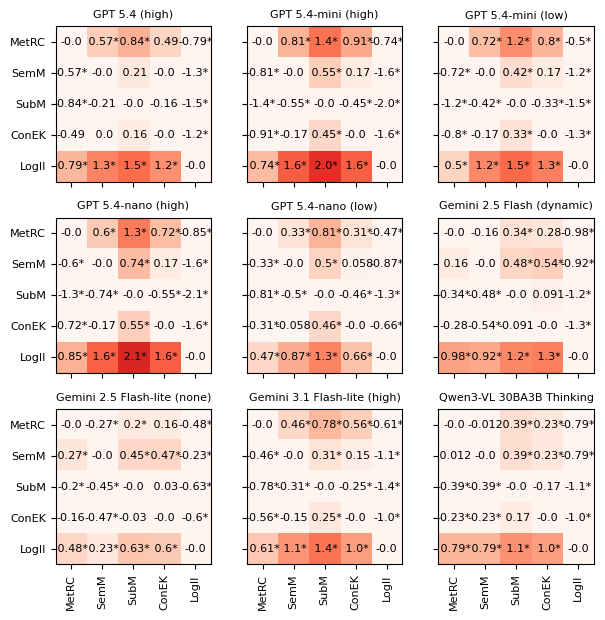

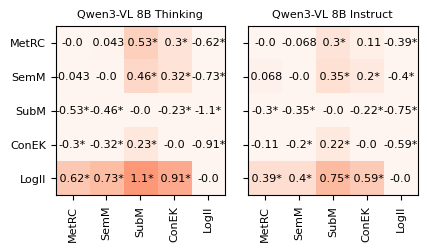

In [434]:
results_by_model = {}
NROWS = 3
NCOLS = 3
NMODELS = NROWS * NCOLS
NIMG = len(model_ids) // NMODELS 
if len(model_ids) % NMODELS != 0:
    NIMG = NIMG + 1

for img_n in range(NIMG):
    start = img_n * NMODELS
    end = start + NMODELS
    n_images = min(end, len(model_ids)) - start

    n_rows = n_images // NCOLS
    if n_images % NCOLS != 0:
        n_rows = n_rows + 1

    fig, axs = plt.subplots(n_rows, NCOLS, figsize=(6.3,6.3), sharex=True, sharey=True)
    for f, filter_id in enumerate(model_ids[start:end]):
        if NCOLS > 1 and n_rows > 1:
            ax = axs[f // NCOLS][f % NCOLS]
        else:
            ax = axs[f]
        #print(f'======================================================{filter_id}===============================================================')
        #convert to error_id -> paper_id -> score_array format
        results_by_item = {}
        for model_id, input_type, error_id, paper_id, score in results:
            if model_id != filter_id:
                continue

            if error_id not in results_by_item:
                results_by_item[error_id] = {}

            curr = results_by_item[error_id]

            if paper_id not in curr:
                curr[paper_id] = []

            curr_list = curr[paper_id]

            curr_list.append(score)

        #convert to error_id -> paper_id -> avg_score format
        scores_by_item = {}
        for error_id, res in results_by_item.items():
            weakness_scores = {}

            for paper_id, score_arr in res.items():
                avg_score = sum(score_arr) / len(score_arr)
                weakness_scores[paper_id] = avg_score

            scores_by_item[error_id] = weakness_scores

        cat_diffs, cat_comparisons_pvalues = category_comparison(scores_by_item)
        category_names = [error_cat_to_acronym[base64.urlsafe_b64decode(k).decode()] for k in categories_list]

        show_x = ((f % NCOLS) == 0)
        show_y = ((f//NCOLS) == NROWS-1)
        im = make_heatmap(ax, model_id_to_name[filter_id], cat_diffs, cat_comparisons_pvalues, category_names, category_names, show_x=show_x, show_y=show_y)
        #print_table_with_pvalues(cat_diffs, cat_comparisons_pvalues, category_names, [''] + category_names)

        #print(f'============================================================================================================================')

    #axs[-1][-1].remove()

    # fig.colorbar(
    #     im,
    #     ax=axs,
    #     label="Value",
    #     shrink=0.1,
    #     orientation='horizontal',
    #     location='bottom'
    # )

    #axs[-1][-1].remove()

    for _ in range((n_rows * NCOLS) - n_images):
        if NCOLS > 1 and n_rows > 1:
            axs[-1][-1].remove()
        else:
            axs[-1].remove()

    fig.tight_layout()
    plt.savefig(f'weakness_diffs_{img_n}.png', dpi=300, bbox_inches='tight')
    #fig.savefig(f'weakness_diffs_{img_n}.png', )

In [356]:
print_table_with_pvalues(cat_diffs, cat_comparisons_pvalues, category_names, [''] + category_names)

                                                       MetRC                 SemM                 SubM                ConEK                LogII 
MetRC                                                   -0.0              -0.0679                0.301*               0.109               -0.393*
SemM                                                  0.0679                 -0.0                0.352*               0.203*              -0.397*
SubM                                                  -0.301*              -0.352*                -0.0                -0.22*              -0.753*
ConEK                                                 -0.109               -0.203*                0.22*                -0.0               -0.587*
LogII                                                  0.393*               0.397*               0.753*               0.587*                -0.0 


In [301]:
a = [1,3,4,5,1,2,3]
b = [1,4,2,4,5,5,1,2]
print(stats.ttest_ind(a, b, equal_var=False))

print((sum(a)/len(a)) - (sum(b)/len(b)))

TtestResult(statistic=np.float64(-0.34727944810393946), pvalue=np.float64(0.7339417576274487), df=np.float64(12.993875095701625))
-0.2857142857142856


## Claim: Models perform the best on Logically Invalid Analysis

In [294]:
results_by_model = {}
FILTER_WEAKNESS = 'LogII'
print(f'======================================================{FILTER_WEAKNESS}===============================================================')
header_format = '{:>40} {:>20} {:>20} {:>20} {:>20} {:>20}'
row_format = '{:40} {:20.3}{:1} {:20.3}{:1} {:20.3}{:1} {:20.3}{:1} {:20.3}{:1}'

category_names = [error_cat_to_acronym[base64.urlsafe_b64decode(k).decode()] for k in list(scores_by_item.keys())]
print(header_format.format('', *category_names))

for filter_id in model_ids:
    results_by_item = {}
    for model_id, input_type, error_id, paper_id, score in results:
        if model_id != filter_id:
            continue

        if error_id not in results_by_item:
            results_by_item[error_id] = {}

        curr = results_by_item[error_id]

        if paper_id not in curr:
            curr[paper_id] = []

        curr_list = curr[paper_id]

        curr_list.append(score)

    scores_by_item = {}
    for error_id, res in results_by_item.items():
        weakness_scores = {}

        for paper_id, score_arr in res.items():
            avg_score = sum(score_arr) / len(score_arr)
            weakness_scores[paper_id] = avg_score

        scores_by_item[error_id] = weakness_scores

    cat_comparisons = np.zeros((len(scores_by_item.keys()),len(scores_by_item.keys())))
    cat_scores1 = np.zeros((len(scores_by_item.keys()),len(scores_by_item.keys())))
    cat_scores2 = np.zeros((len(scores_by_item.keys()),len(scores_by_item.keys())))

    for i, category1 in enumerate(scores_by_item.keys()):
        cat1_dict = scores_by_item[category1]
        for j, category2 in enumerate(scores_by_item.keys()):
            cat2_dict = scores_by_item[category2]

            common_keys = set(cat1_dict.keys()).intersection(set(cat2_dict.keys()))
            cat1_scores = [cat1_dict[k] for k in common_keys]
            cat2_scores = [cat2_dict[k] for k in common_keys]

            #print(stats.ttest_ind(cat1_scores, cat2_scores, equal_var=False).pvalue)
            cat_comparisons[i][j] = stats.ttest_ind(cat1_scores, cat2_scores, equal_var=False).pvalue
            cat_scores1[i][j] = sum(cat1_scores)/len(cat1_scores)
            cat_scores2[i][j] = sum(cat2_scores)/len(cat2_scores)

    #header_format = '{:>5} {:>20} {:>20} {:>20} {:>20} {:>20}'
    #row_format = '{:5} {:20.3} {:20.3} {:20.3} {:20.3} {:20.3}'

    category_names = [error_cat_to_acronym[base64.urlsafe_b64decode(k).decode()] for k in list(scores_by_item.keys())]
    #print(header_format.format('', *category_names))
    for i, k1 in enumerate(scores_by_item.keys()):
        cat = category_names[i]

        if cat != FILTER_WEAKNESS:
            continue


        cat_pvalues = cat_comparisons[i]

        #print(row_format.format(filter_id, *cat_pvalues))
        diffs = [a-b for a,b in zip(cat_scores1[i], cat_scores2[i])]
        #print(row_format.format(f'  {FILTER_WEAKNESS}', *cat_scores1[i]))
        #print(row_format.format(f'  other', *cat_scores2[i]))

        print_vals = []
        for i, diff in enumerate(diffs):
            print_vals.append(diff)
            sig = '*' if cat_pvalues[i] < 0.05 else ''
            print_vals.append(sig)

        print(row_format.format(filter_id, *print_vals))

print('================================================================================================================================================')

======================================================LogII===============================================================
                                                        MetRC                 SemM                 SubM                ConEK                LogII
gpt_54                                                  0.787*                 1.26*                 1.47*                 1.15*                  0.0 
gpt_54_mini                                              0.74*                  1.6*                  2.0*                 1.59*                  0.0 
gpt_54_mini_low                                           0.5*                 1.21*                 1.51*                  1.3*                  0.0 
gpt_54_nano                                             0.847*                 1.56*                 2.09*                 1.57*                  0.0 
gpt_54_nano_low                                         0.467*                0.872*                 1.25*                0.659

In [251]:
results_by_item

{'bWV0aG9kb2xvZ3lfcmVzdWx0X2NvbmZsaWN0': {'2409.14664': [2,
   1,
   2,
   1,
   2,
   2,
   2,
   2,
   4,
   2,
   2,
   2,
   1,
   2,
   2,
   4,
   5,
   5,
   3,
   2,
   2,
   1,
   1,
   4,
   2,
   2,
   2,
   2,
   2,
   1,
   2,
   2,
   2],
  '2505.13988': [2,
   2,
   2,
   1,
   2,
   2,
   2,
   2,
   5,
   1,
   2,
   2,
   2,
   2,
   2,
   5,
   5,
   5,
   1,
   2,
   2,
   3,
   2,
   2,
   2,
   2,
   2,
   2,
   5,
   5,
   2,
   2,
   2],
  '2502.10118': [1,
   5,
   5,
   2,
   4,
   2,
   2,
   2,
   2,
   1,
   2,
   2,
   2,
   2,
   2,
   5,
   5,
   5,
   2,
   2,
   2,
   1,
   2,
   5,
   2,
   5,
   4,
   4,
   5,
   5,
   2,
   2,
   2],
  '2501.09751': [2,
   2,
   2,
   2,
   5,
   5,
   2,
   5,
   2,
   2,
   2,
   1,
   2,
   1,
   2,
   5,
   2,
   5,
   2,
   2,
   2,
   5,
   4,
   5,
   2,
   2,
   2,
   2,
   5,
   2,
   2,
   2,
   1],
  '2509.01093': [3,
   4,
   4,
   1,
   4,
   4,
   2,
   5,
   4,
   3,
   4,
   1,
   1,
   2,
   1,
   5

In [ ]:
for i, k1 in enumerate(scores_by_item.keys()):
    cat = category_names[i]
    
    cat_pvalues = cat_comparisons[i]
    print(row_format.format(cat, *cat_pvalues))

In [236]:
cat_comparisons[i]

array([3.80131334e-08, 1.95808268e-17, 2.05470583e-24, 2.71172861e-18,
       1.00000000e+00])

In [ ]:

error_cat = list(scores_by_item.keys())[0]
base64.urlsafe_b64encode(error_cat.encode()).decode()

base64.urlsafe_b64decode(error_cat).decode()

# Surface-Based Similarity metrics

These metrics are based on token overlap.

* Rouge-L: Based on the longest common subsequence. Used frequentyly in summarization.
* BLEU: Frequently used for translartion.
* BERTScore: Contextualized representations for each token, then computes similarity.

In [12]:
def evaluate_generated2(responses, metric_name, score_key, additional_kwargs):
    metric = evaluate.load(metric_name)
    generated_with_gold = {}
    for paper_id, error_id, res in responses:
        if 'model_responses' in res:
            ground_truth = None
            for gr in res['ground_truth']:
                if gr['task_id'] == 'generate_ground_truth_description':
                    ground_truth = gr['response_text']
                    break
   
            if ground_truth is None:
                raise Exception('No ground truth')
            
            for model_response in res['model_responses']:
                model_id = model_response['model_id']
                input_type = model_response['input_type']
                meta_id = f'{model_id}___{input_type}___{error_id}'

                if meta_id not in generated_with_gold:
                    generated_with_gold[meta_id] = {
                        'generated': [],
                        'ground_truth': [],
                    }
                
                generated = model_response['response_text']
                if generated is None or len(generated) == 0:
                    continue

                generated_with_gold[meta_id]['generated'].append(generated)
                generated_with_gold[meta_id]['ground_truth'].append([ground_truth])

    scores = {}

    for i, item in enumerate(generated_with_gold.items()):
        if i % 20 == 0:
            print(i)

        meta_id, generated_and_gold = item
        generated = generated_and_gold['generated']
        references = generated_and_gold['ground_truth']
        score = metric.compute(predictions=generated, references=references, **additional_kwargs)[score_key]
        scores[meta_id] = scores.get(meta_id, []) + [score]

    return scores

In [13]:
def print_table(scores):
    print(r'\begin{tabular}{c|ccccc}')
    print(r'    \toprule')
    #print(r'    Model & \multicolumn{5}{|c|}{images} & \multicolumn{5}{|c|}{latex} & \multicolumn{5}{|c|}{images_and_latex} \\')
    print(r'    Model & ' + ' & '.join(error_category_acronyms) + r' \\')
    print(r'    \midrule')

    for model_id in model_ids:
        model_name = model_id_to_name[model_id]
        model_row = f'   {model_name} & ' + '& ' * (len(error_category_acronyms)-1) + r' \\'
        print(model_row)
        print(r'    \midrule')
        for input_type in input_types:
            input_name = input_types_to_name[input_type]
            outp = f'   {input_name} & '
            for error_cat in error_categories:
                error_cat_b64 = base64.urlsafe_b64encode(error_cat.encode()).decode()
                score_array = scores[f'{model_id}___{input_type}___{error_cat_b64}']
                score = np.mean(score_array)
                outp += f'{score:.2} & '
            print(outp[:-2] + r'\\' )

        print(r'    \midrule')
    print(r'\bottomrule')
    print(r'\end{tabular}')

In [14]:
def print_merged_table(metric1_scores, metric1_name, metric2_scores, metric2_name):
    print(r'\begin{tabular}{c|ccccc|ccccc}')
    print(r'    \toprule')
    #print(r'    Model & \multicolumn{5}{|c|}{images} & \multicolumn{5}{|c|}{latex} & \multicolumn{5}{|c|}{images_and_latex} \\')
    print(r' & \multicolumn{5}{c}{'+f'{metric1_name}'+r'} & \multicolumn{5}{c}{'+f'{metric2_name}'+r'} \\')
    print(r'    Model & ' + ' & '.join(error_category_acronyms) + ' & ' + ' & '.join(error_category_acronyms) + r' \\')
    print(r'    \midrule')

    for model_id in model_ids:
        model_name = model_id_to_name[model_id]
        model_row = f'   {model_name} & ' + '& ' * (len(error_category_acronyms)-1) + r' \\'
        print(model_row)
        print(r'    \midrule')
        for input_type in input_types:
            input_name = input_types_to_name[input_type]
            outp = f'   {input_name} & '
            for metric_scores in [metric1_scores, metric2_scores]:
                scores = metric_scores
                for error_cat in error_categories:
                    error_cat_b64 = base64.urlsafe_b64encode(error_cat.encode()).decode()
                    score_array = scores[f'{model_id}___{input_type}___{error_cat_b64}']
                    score = np.mean(score_array)
                    outp += f'{score:.2f} & '
            print(outp[:-2] + r'\\' )

        print(r'    \midrule')
    print(r'\bottomrule')
    print(r'\end{tabular}')

## Rouge

In [15]:
rouge = evaluate_generated2(responses, "rouge", "rougeL", {"use_aggregator": False})

0
20
40
60
80
100
120
140
160


In [16]:
rouge

{'gpt_54_nano_low___images___bWV0aG9kb2xvZ3lfcmVzdWx0X2NvbmZsaWN0': [[0.0867208672086721,
   0.09923664122137404,
   0.10882708585247884,
   0.0844205679201842,
   0.1059190031152648,
   0.06384558277654045,
   0.08860759493670885,
   0.15537190082644628,
   0.0899100899100899,
   0.10612991765782251,
   0.14285714285714285,
   0.07973962571196094,
   0.10362694300518135,
   0.09099018733273863,
   0.08326253186066271,
   0.06879606879606881,
   0.06686930091185411,
   0.13194444444444445,
   0.10644831115660186,
   0.09836065573770492,
   0.08990536277602522,
   0.09534127843986999,
   0.1,
   0.09395973154362416,
   0.07761194029850746,
   0.11235955056179775,
   0.07586206896551724,
   0.08386508659981769,
   0.11313131313131314,
   0.09710550887021475,
   0.18448637316561844,
   0.09368191721132897,
   0.07566024268379729,
   0.19937694704049844,
   0.0798004987531172,
   0.07636363636363637,
   0.09793103448275861,
   0.09706959706959706,
   0.1016949152542373,
   0.11958146487294

In [17]:
print_table(rouge)

\begin{tabular}{c|ccccc}
    \toprule
    Model & ConEK & LogII & MetRC & SemM & SubM \\
    \midrule
   GPT 5.4 (high) & & & & &  \\
    \midrule
   Images & 0.11 & 0.15 & 0.12 & 0.12 & 0.12 \\
   Latex & 0.11 & 0.13 & 0.12 & 0.12 & 0.12 \\
   Images \& Latex & 0.11 & 0.13 & 0.11 & 0.12 & 0.12 \\
    \midrule
   GPT 5.4-mini (high) & & & & &  \\
    \midrule
   Images & 0.13 & 0.19 & 0.15 & 0.15 & 0.14 \\
   Latex & 0.14 & 0.2 & 0.16 & 0.15 & 0.14 \\
   Images \& Latex & 0.13 & 0.17 & 0.15 & 0.14 & 0.13 \\
    \midrule
   GPT 5.4-mini (low) & & & & &  \\
    \midrule
   Images & 0.13 & 0.18 & 0.15 & 0.14 & 0.13 \\
   Latex & 0.13 & 0.17 & 0.15 & 0.14 & 0.13 \\
   Images \& Latex & 0.12 & 0.17 & 0.15 & 0.13 & 0.13 \\
    \midrule
   GPT 5.4-nano (high) & & & & &  \\
    \midrule
   Images & 0.12 & 0.17 & 0.13 & 0.13 & 0.13 \\
   Latex & 0.13 & 0.18 & 0.14 & 0.13 & 0.12 \\
   Images \& Latex & 0.12 & 0.19 & 0.14 & 0.13 & 0.12 \\
    \midrule
   GPT 5.4-nano (low) & & & & &  \\
    \midr

## BERTScore

In [18]:
bertscore = evaluate_generated2(responses, "bertscore", "recall", {"lang": "en"})

0


/Users/aadi.joshi/miniconda3/envs/general/lib/python3.13/site-packages/huggingface_hub/file_download.py:943: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


KeyboardInterrupt: 

In [ ]:
print_merged_table(rouge, 'Rouge-L', bertscore, 'BERTScore (Recall)')

\begin{tabular}{c|ccccc|ccccc}
    \toprule
 & \multicolumn{5}{c}{Rouge-L} & \multicolumn{5}{c}{BERTScore (Recall)} \\
    Model & ConEK & LogII & MetRC & SemM & SubM & ConEK & LogII & MetRC & SemM & SubM \\
    \midrule
   GPT 5.4 & & & & &  \\
    \midrule
   Images & 0.11 & 0.15 & 0.12 & 0.12 & 0.12 & 0.83 & 0.86 & 0.84 & 0.82 & 0.82 \\
   Latex & 0.11 & 0.13 & 0.12 & 0.12 & 0.12 & 0.84 & 0.86 & 0.85 & 0.83 & 0.83 \\
   Images \& Latex & 0.11 & 0.13 & 0.11 & 0.12 & 0.12 & 0.83 & 0.86 & 0.84 & 0.83 & 0.82 \\
    \midrule
   GPT 5.4-mini (high) & & & & &  \\
    \midrule
   Images & 0.13 & 0.19 & 0.15 & 0.15 & 0.14 & 0.83 & 0.86 & 0.84 & 0.83 & 0.83 \\
   Latex & 0.14 & 0.20 & 0.16 & 0.15 & 0.14 & 0.83 & 0.87 & 0.85 & 0.84 & 0.83 \\
   Images \& Latex & 0.13 & 0.17 & 0.15 & 0.14 & 0.13 & 0.83 & 0.86 & 0.84 & 0.83 & 0.82 \\
    \midrule
   GPT 5.4-nano (high) & & & & &  \\
    \midrule
   Images & 0.12 & 0.17 & 0.13 & 0.13 & 0.13 & 0.83 & 0.85 & 0.83 & 0.82 & 0.82 \\
   Latex & 0.13 & 

# Human-Validated Subset

In [28]:
rouge_score_human_valid = {}

#paper ids should be in same order]
filter_mask = {}
for model, input_type, error_id, paper_id, score, human_valid in results:
    meta_id = f'{model}___{input_type}___{error_id}'
    filter_mask[meta_id] = filter_mask.get(meta_id, []) + [human_valid == 1]

In [29]:
for k, v in filter_mask.items():
    print(k)
    print(len(v))
    print(len(bertscore[k][0]))
    print(len(rouge[k][0]))
    assert len(v) == len(bertscore[k][0]) == len(rouge[k][0])

gpt_54_nano_low___images___bWV0aG9kb2xvZ3lfcmVzdWx0X2NvbmZsaWN0
55


NameError: name 'bertscore' is not defined

In [ ]:
bertscore_human_validated = {}
rouge_human_validated = {}
for k, v in filter_mask.items():
    bertscore_human_validated[k] = [s for s, valid in zip(bertscore[k][0], v) if valid]
    rouge_human_validated[k] = [s for s, valid in zip(rouge[k][0], v) if valid]

In [ ]:
print_merged_table(rouge_human_validated, 'Rouge-L', bertscore_human_validated, 'BERTScore (Recall)', precision=2)

\begin{tabular}{c|ccccc|ccccc}
    \toprule
 & \multicolumn{5}{c}{Rouge-L} & \multicolumn{5}{c}{BERTScore (Recall)} \\
    Model & ConEK & LogII & MetRC & SemM & SubM & ConEK & LogII & MetRC & SemM & SubM \\
    \midrule
   GPT 5.4 & & & & &  \\
    \midrule
   Images & 0.11 & 0.15 & 0.11 & 0.13 & 0.12 & 0.83 & 0.85 & 0.84 & 0.83 & 0.82 \\
   Latex & 0.11 & 0.14 & 0.12 & 0.12 & 0.12 & 0.84 & 0.86 & 0.85 & 0.83 & 0.83 \\
   Images \& Latex & 0.10 & 0.13 & 0.11 & 0.12 & 0.12 & 0.84 & 0.85 & 0.84 & 0.83 & 0.83 \\
    \midrule
   GPT 5.4-mini (high) & & & & &  \\
    \midrule
   Images & 0.12 & 0.19 & 0.14 & 0.15 & 0.13 & 0.83 & 0.85 & 0.83 & 0.83 & 0.82 \\
   Latex & 0.13 & 0.20 & 0.15 & 0.15 & 0.13 & 0.83 & 0.87 & 0.85 & 0.84 & 0.82 \\
   Images \& Latex & 0.13 & 0.17 & 0.14 & 0.14 & 0.13 & 0.83 & 0.86 & 0.84 & 0.83 & 0.82 \\
    \midrule
   GPT 5.4-nano (high) & & & & &  \\
    \midrule
   Images & 0.12 & 0.17 & 0.13 & 0.13 & 0.12 & 0.83 & 0.85 & 0.83 & 0.82 & 0.82 \\
   Latex & 0.12 & 

In [ ]:
print_table(bertscore)

\begin{tabular}{c|ccccc}
    \toprule
    Model & ConEK & LogII & MetRC & SemM & SubM \\
    \midrule
   GPT 5.4 & & & & &  \\
    \midrule
   Images & 0.83 & 0.86 & 0.84 & 0.81 & 0.82 \\
   Latex & 0.84 & 0.86 & 0.85 & 0.83 & 0.83 \\
   Images \& Latex & 0.83 & 0.86 & 0.84 & 0.83 & 0.82 \\
    \midrule
   GPT 5.4-mini & & & & &  \\
    \midrule
   Images & 0.83 & 0.86 & 0.84 & 0.83 & 0.83 \\
   Latex & 0.83 & 0.87 & 0.85 & 0.84 & 0.83 \\
   Images \& Latex & 0.83 & 0.86 & 0.84 & 0.83 & 0.82 \\
    \midrule
   GPT 5.4-nano & & & & &  \\
    \midrule
   Images & 0.83 & 0.85 & 0.83 & 0.82 & 0.82 \\
   Latex & 0.84 & 0.87 & 0.85 & 0.84 & 0.83 \\
   Images \& Latex & 0.84 & 0.87 & 0.84 & 0.84 & 0.82 \\
    \midrule
   Gemini 2.5 Flash & & & & &  \\
    \midrule
   Images & 0.81 & 0.82 & 0.82 & 0.81 & 0.81 \\
   Latex & 0.83 & 0.84 & 0.83 & 0.83 & 0.83 \\
   Images \& Latex & 0.83 & 0.84 & 0.83 & 0.83 & 0.82 \\
    \midrule
   Gemini 2.5 Flash-lite & & & & &  \\
    \midrule
   Images & 0.8